In [3]:
import sys
import re
import json
from pathlib import Path
from datetime import datetime
from collections import defaultdict

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from IPython.display import display

# Same local modules as your existing ARISTA notebook.
for folder in ["../src", "../../paste3/src", "../../paste3/src/paste3"]:
    if folder not in sys.path:
        sys.path.append(folder)

from align import *
from glmpca import *
from helper import *
from model_selection import *
from paste import *
from visualization import *
from sampler_cached import fused_tlb
from pathlib import Path
DATA_DIR = Path("../../Data/ARISTA")
N_HVG = 10_000

OUT = (
    Path.cwd()
    / f"ARISTA_ensemble_{datetime.now():%Y%m%d_%H%M%S_%f}"
).resolve()
OUT.mkdir(parents=True)

def dpi_of(path):
    match = re.match(r"(\d+)DPI", Path(path).name)
    if match is None:
        raise ValueError(f"Cannot identify DPI: {path}")
    return int(match.group(1))

groups = defaultdict(list)
for file in sorted(DATA_DIR.glob("*DPI*.h5ad")):
    groups[dpi_of(file)].append(file)

T = sorted(groups)[:5]
if len(T) != 5:
    raise ValueError(f"Expected at least five time points; found {T}")

groups = {t: groups[t] for t in T}
print("Time points used:", T)

# Shared genes across the selected five time points only.
gene_sets = []
for t in T:
    for file in groups[t]:
        a = sc.read_h5ad(file, backed="r")
        try:
            if not a.var_names.is_unique:
                raise ValueError(f"Duplicate gene IDs in {file}")
            gene_sets.append(set(a.var_names))
        finally:
            a.file.close()

common_genes = sorted(set.intersection(*gene_sets))
if not common_genes:
    raise ValueError("No shared genes across sections")

def crop_outliers(a, n_mad=6):
    xy = np.asarray(a.obsm["spatial"], dtype=float)
    if not np.isfinite(xy).all():
        raise ValueError("Nonfinite spatial coordinates")
    distance = np.linalg.norm(xy - np.median(xy, axis=0), axis=1)
    median = np.median(distance)
    mad = np.median(np.abs(distance - median)) + 1e-9
    return a[distance <= median + n_mad * mad].copy()

def load_section(file):
    a = sc.read_h5ad(file)
    if "counts" not in a.layers:
        raise KeyError(f"{file}: missing layers['counts']")

    mask = (
        (a.obs["inj_uninj"] == "inj")
        & (a.obs["D_V"] == "D")
    )
    a = a[mask, common_genes].copy()
    if a.n_obs == 0:
        raise ValueError(f"{file}: no injured-dorsal spots")

    a = crop_outliers(a)
    a.X = a.layers["counts"].copy()
    a.obs["slice"] = file.stem
    a.obs["time"] = dpi_of(file)
    return a

parts = [
    load_section(file)
    for t in T
    for file in groups[t]
]
ensemble_data = ad.concat(parts, join="inner", merge="same")
ensemble_data.obs_names_make_unique()
del parts

# Global QC, matching your notebook.
sc.pp.calculate_qc_metrics(
    ensemble_data, percent_top=None, inplace=True
)
max_genes = float(
    ensemble_data.obs["n_genes_by_counts"].quantile(0.999)
)
sc.pp.filter_cells(ensemble_data, min_genes=200)
sc.pp.filter_cells(ensemble_data, max_genes=max_genes)
sc.pp.filter_genes(ensemble_data, min_cells=3)
ensemble_data.layers["counts"] = ensemble_data.X.copy()

# Shared, batch-aware HVGs across all retained sections.
sc.pp.normalize_total(ensemble_data, target_sum=1e4)
sc.pp.log1p(ensemble_data)
sc.pp.highly_variable_genes(
    ensemble_data,
    n_top_genes=min(N_HVG, ensemble_data.n_vars),
    batch_key="slice",
    subset=True,
)

tp_data = {
    t: ensemble_data[ensemble_data.obs["time"] == t].copy()
    for t in T
}

# Ensure QC did not remove an entire section.
for t in T:
    expected = {f.stem for f in groups[t]}
    observed = set(tp_data[t].obs["slice"].astype(str))
    if expected != observed:
        raise ValueError(
            f"{t} DPI: sections lost during QC: {expected - observed}"
        )
    print(
        f"{t} DPI: {tp_data[t].n_obs:,} spots; "
        f"{len(observed)} sections"
    )

ensemble_data.write_h5ad(
    OUT / "section_pool.h5ad", compression="gzip"
)
del ensemble_data

print(f"\nOutput folder:\n{OUT}")

Time points used: [2, 5, 10, 15, 20]


/tmp/ipykernel_1484413/3078804038.py:104: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  ensemble_data = ad.concat(parts, join="inner", merge="same")


2 DPI: 5,700 spots; 3 sections
5 DPI: 6,302 spots; 3 sections
10 DPI: 7,147 spots; 3 sections
15 DPI: 8,983 spots; 4 sections
20 DPI: 9,044 spots; 3 sections

Output folder:
/home/zhaow/SlicingBias/notebooks/ARISTA_ensemble_20261102_123358_609155


In [4]:
for t in T:
    counts = (
        tp_data[t].obs["slice"]
        .astype(str)
        .value_counts()
        .sort_index()
    )

    print(f"\n{t} DPI: {counts.sum():,} spots; {len(counts)} sections")
    for section, n_spots in counts.items():
        print(f"  {section}: {n_spots:,} spots")


2 DPI: 5,700 spots; 3 sections
  2DPI_1: 1,824 spots
  2DPI_2: 1,820 spots
  2DPI_3: 2,056 spots

5 DPI: 6,302 spots; 3 sections
  5DPI_1: 2,035 spots
  5DPI_2: 2,154 spots
  5DPI_3: 2,113 spots

10 DPI: 7,147 spots; 3 sections
  10DPI_1: 2,322 spots
  10DPI_2: 2,499 spots
  10DPI_3: 2,326 spots

15 DPI: 8,983 spots; 4 sections
  15DPI_1: 2,128 spots
  15DPI_2: 2,189 spots
  15DPI_3: 2,165 spots
  15DPI_4: 2,501 spots

20 DPI: 9,044 spots; 3 sections
  20DPI_1: 2,846 spots
  20DPI_2: 3,113 spots
  20DPI_3: 3,085 spots


In [5]:
import gc
import pickle
import time

def section_names_at(t):
    return sorted(tp_data[t].obs["slice"].astype(str).unique())

def section_at(t, name):
    return tp_data[t][
        tp_data[t].obs["slice"].astype(str) == name
    ].copy()

# Reference pair: first sections at the two central retained stages.
ta_ref, tb_ref = T[len(T) // 2:len(T) // 2 + 2]
sa_ref = section_names_at(ta_ref)[0]
sb_ref = section_names_at(tb_ref)[0]

A0 = section_at(ta_ref, sa_ref)
B0 = section_at(tb_ref, sb_ref)

M0 = dissimilarity_metric(
    "euc", A0, B0,
    to_dense_array(A0.X).double(),
    to_dense_array(B0.X).double(),
).cpu().numpy()

positive = M0[M0 > 0]
if positive.size == 0:
    raise ValueError("Cannot determine feature scale")
FEAT_SCALE = float(np.median(positive))

D0 = cdist(
    np.asarray(A0.obsm["spatial"], dtype=float),
    np.asarray(A0.obsm["spatial"], dtype=float),
)
positive = D0[D0 > 0]
if positive.size == 0:
    raise ValueError("Cannot determine spatial scale")
SPATIAL_SCALE = float(np.median(positive))

del A0, B0, M0, D0, positive
gc.collect()

ARGS = dict(
    alpha=0.5,
    exp_metric="euc",
    feat_scale=FEAT_SCALE,
    spatial_scale=SPATIAL_SCALE,
    solver="pot",
    max_spots=10_000,
    seed=0,
)

print(f"Reference: {sa_ref} -> {sb_ref}")
print(
    f"Feature scale={FEAT_SCALE:.4g}; "
    f"spatial scale={SPATIAL_SCALE:.4g}"
)

cost_tensors_lower = {}
COST_DIR = OUT / "ftlb_costs"
COST_DIR.mkdir(exist_ok=True)

for ta, tb in zip(T[:-1], T[1:]):
    sa, sb = section_names_at(ta), section_names_at(tb)
    C = np.zeros((len(sa), len(sb)))

    for i, source in enumerate(sa):
        A = section_at(ta, source)
        for j, target in enumerate(sb):
            B = section_at(tb, target)
            started = time.perf_counter()

            value, _, _ = fused_tlb(A, B, K=200, **ARGS)
            C[i, j] = float(value)

            print(
                f"{source} -> {target}: "
                f"{C[i, j]:.4f} "
                f"({time.perf_counter() - started:.1f}s)",
                flush=True,
            )
            del B
            gc.collect()
        del A

    if not np.isfinite(C).all():
        raise ValueError(f"Nonfinite costs at {ta}->{tb}")

    cost_tensors_lower[(ta, tb)] = (C, sa, sb)
    pd.DataFrame(C, index=sa, columns=sb).to_csv(
        COST_DIR / f"{ta}DPI_to_{tb}DPI.csv"
    )

    # Checkpoint completed transitions.
    with open(OUT / "cost_tensors_lower.pkl", "wb") as f:
        pickle.dump(cost_tensors_lower, f)

with open(OUT / "ftlb_settings.json", "w") as f:
    json.dump({
        **ARGS,
        "K": 200,
        "times": list(map(int, T)),
        "reference_sections": [sa_ref, sb_ref],
    }, f, indent=2)

print("\nAll four consecutive transitions finished.")

Reference: 10DPI_1 -> 15DPI_1
Feature scale=64.08; spatial scale=1056
2DPI_1 -> 5DPI_1: 0.4981 (2.4s)
2DPI_1 -> 5DPI_2: 0.4944 (2.5s)
2DPI_1 -> 5DPI_3: 0.5000 (2.3s)
2DPI_2 -> 5DPI_1: 0.4900 (2.2s)
2DPI_2 -> 5DPI_2: 0.4852 (2.3s)
2DPI_2 -> 5DPI_3: 0.4877 (2.4s)
2DPI_3 -> 5DPI_1: 0.4929 (2.5s)
2DPI_3 -> 5DPI_2: 0.4869 (2.4s)
2DPI_3 -> 5DPI_3: 0.4871 (2.4s)
5DPI_1 -> 10DPI_1: 0.4925 (2.7s)
5DPI_1 -> 10DPI_2: 0.4929 (3.0s)
5DPI_1 -> 10DPI_3: 0.4942 (3.0s)
5DPI_2 -> 10DPI_1: 0.4881 (2.8s)
5DPI_2 -> 10DPI_2: 0.4882 (3.0s)
5DPI_2 -> 10DPI_3: 0.4892 (3.0s)
5DPI_3 -> 10DPI_1: 0.4890 (2.9s)
5DPI_3 -> 10DPI_2: 0.4869 (3.0s)
5DPI_3 -> 10DPI_3: 0.4861 (2.8s)
10DPI_1 -> 15DPI_1: 0.4834 (3.0s)
10DPI_1 -> 15DPI_2: 0.4886 (3.2s)
10DPI_1 -> 15DPI_3: 0.4966 (2.9s)
10DPI_1 -> 15DPI_4: 0.4957 (3.5s)
10DPI_2 -> 15DPI_1: 0.4838 (3.5s)
10DPI_2 -> 15DPI_2: 0.4871 (3.5s)
10DPI_2 -> 15DPI_3: 0.4965 (3.2s)
10DPI_2 -> 15DPI_4: 0.4923 (3.6s)
10DPI_3 -> 15DPI_1: 0.4823 (3.1s)
10DPI_3 -> 15DPI_2: 0.4821 (3.2s)
10DPI

,path_id,2,5,10,15,20,path_probability,log_path_probability,ensemble_weight,fit_id
0,path_01,2DPI_3,5DPI_3,10DPI_3,15DPI_4,20DPI_3,0.010600,-4.546906,0.127310,fit_01
1,path_02,2DPI_1,5DPI_1,10DPI_1,15DPI_1,20DPI_1,0.010383,-4.567547,0.124709,fit_02
2,path_03,2DPI_3,5DPI_3,10DPI_3,15DPI_4,20DPI_2,0.009185,-4.690214,0.110312,fit_03
3,path_04,2DPI_1,5DPI_2,10DPI_1,15DPI_1,20DPI_1,0.008177,-4.806378,0.098214,fit_04
4,path_05,2DPI_2,5DPI_1,10DPI_1,15DPI_1,20DPI_1,0.007724,-4.863401,0.092771,fit_05
5,path_06,2DPI_2,5DPI_3,10DPI_3,15DPI_4,20DPI_3,0.007622,-4.876672,0.091548,fit_06
6,path_07,2DPI_3,5DPI_3,10DPI_3,15DPI_2,20DPI_3,0.007618,-4.877266,0.091493,fit_07
7,path_08,2DPI_2,5DPI_2,10DPI_1,15DPI_1,20DPI_1,0.007527,-4.889210,0.090407,fit_08
8,path_09,2DPI_3,5DPI_3,10DPI_3,15DPI_2,20DPI_2,0.007222,-4.930670,0.086735,fit_09
9,path_10,2DPI_3,5DPI_3,10DPI_2,15DPI_1,20DPI_1,0.007202,-4.933382,0.086500,fit_10


Selected 10 distinct paths
Total probability mass retained: 8.33%


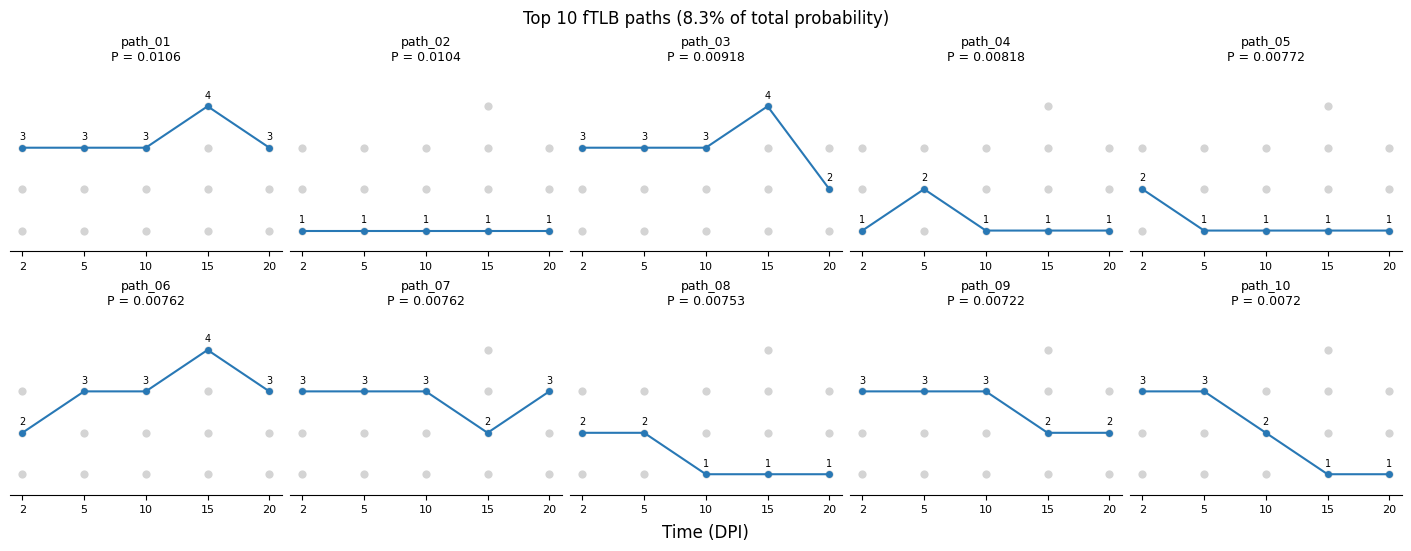


Use this OUT folder for STORIES:
/home/zhaow/SlicingBias/notebooks/ARISTA_ensemble_20261102_123358_609155


In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot
from IPython.display import display

N_PATHS = 10
REG_FRAC = 0.01

section_names = {}
transitions = {}
initial_mass = None

# ---------------- OT transition probabilities ----------------
for ta, tb in zip(T[:-1], T[1:]):
    C, sa, sb = cost_tensors_lower[(ta, tb)]
    C = np.asarray(C, dtype=float)
    sa, sb = list(map(str, sa)), list(map(str, sb))

    if C.shape != (len(sa), len(sb)) or not np.isfinite(C).all():
        raise ValueError(f"Invalid costs at {ta}->{tb}")

    if ta in section_names and section_names[ta] != sa:
        raise ValueError(f"Inconsistent section order at {ta} DPI")
    section_names[ta], section_names[tb] = sa, sb

    p = np.full(len(sa), 1 / len(sa))
    q = np.full(len(sb), 1 / len(sb))
    reg = REG_FRAC * max(float(C.max()), 1e-9)

    G = np.asarray(ot.sinkhorn(
        p, q, C, reg,
        method="sinkhorn_log",
        numItermax=50_000,
        stopThr=1e-10,
    ))

    error = max(
        np.max(np.abs(G.sum(axis=1) - p)),
        np.max(np.abs(G.sum(axis=0) - q)),
    )
    if (
        not np.isfinite(G).all()
        or np.any(G < 0)
        or error > 1e-6
    ):
        raise RuntimeError(
            f"Invalid coupling at {ta}->{tb}; "
            f"marginal error={error:.2e}"
        )

    if initial_mass is None:
        initial_mass = p

    transitions[(ta, tb)] = G / G.sum(axis=1, keepdims=True)

# ---------------- Exact top-k paths ----------------
# For each current section, retain its k highest-probability
# prefixes. Work in log probability to avoid underflow.
best = {
    i: [(float(np.log(prob)), (i,))]
    for i, prob in enumerate(initial_mass)
    if prob > 0
}

for ta, tb in zip(T[:-1], T[1:]):
    P = transitions[(ta, tb)]
    next_best = {}

    for j in range(P.shape[1]):
        candidates = []
        for i, prefixes in best.items():
            if P[i, j] <= 0:
                continue
            log_transition = float(np.log(P[i, j]))
            candidates.extend(
                (log_prob + log_transition, indices + (j,))
                for log_prob, indices in prefixes
            )

        # Index tuple provides deterministic tie breaking.
        candidates.sort(key=lambda item: (-item[0], item[1]))
        if candidates:
            next_best[j] = candidates[:N_PATHS]

    best = next_best

ranked = sorted(
    [item for prefixes in best.values() for item in prefixes],
    key=lambda item: (-item[0], item[1]),
)[:N_PATHS]

if not ranked:
    raise RuntimeError("No positive-probability paths found")

# Relative weights within the selected top-k set.
log_probs = np.array([item[0] for item in ranked])
relative = np.exp(log_probs - log_probs.max())
weights = relative / relative.sum()

records = []
for k, ((log_prob, indices), weight) in enumerate(
    zip(ranked, weights), start=1
):
    selected = [
        section_names[t][i]
        for t, i in zip(T, indices)
    ]
    records.append({
        "path_id": f"path_{k:02d}",
        **{str(t): s for t, s in zip(T, selected)},
        "path_probability": float(np.exp(log_prob)),
        "log_path_probability": float(log_prob),
        "ensemble_weight": float(weight),
        "fit_id": f"fit_{k:02d}",
    })

paths_df = pd.DataFrame(records)
retained_mass = float(paths_df["path_probability"].sum())

# Keep compatible filenames for the existing STORIES block.
paths_df.to_csv(OUT / "sampled_paths.csv", index=False)
paths_df.to_csv(OUT / "top_probability_paths.csv", index=False)

with open(OUT / "sampling_settings.json", "w") as f:
    json.dump({
        "selection": "top_joint_probability",
        "times": list(map(int, T)),
        "n_paths": len(paths_df),
        "reg_frac": REG_FRAC,
        "retained_probability_mass": retained_mass,
        "section_names": {
            str(t): section_names[t] for t in T
        },
    }, f, indent=2)

display(paths_df)
print(f"Selected {len(paths_df)} distinct paths")
print(f"Total probability mass retained: {retained_mass:.2%}")

# ---------------- Plot selected paths ----------------
# Vertical positions indicate section identity, not anatomical depth.
fig, axes = plt.subplots(
    2, 5, figsize=(14, 5.4),
    sharex=True, constrained_layout=True,
)
max_sections = max(len(v) for v in section_names.values())

for ax, (_, row) in zip(axes.flat, paths_df.iterrows()):
    for k, t in enumerate(T):
        ax.scatter(
            np.full(len(section_names[t]), k),
            np.arange(len(section_names[t])),
            color="0.83", s=24, zorder=1,
        )

    y = [
        section_names[t].index(row[str(t)])
        for t in T
    ]
    ax.plot(
        range(len(T)), y, "-o",
        color="#2878B5", markersize=4, zorder=2,
    )

    for k, t in enumerate(T):
        suffix = row[str(t)].split("DPI", 1)[-1].lstrip("_")
        ax.annotate(
            suffix or "1", (k, y[k]),
            xytext=(0, 6), textcoords="offset points",
            ha="center", fontsize=7,
        )

    ax.set_title(
        f"{row['path_id']}\n"
        f"P = {row['path_probability']:.3g}",
        fontsize=9,
    )
    ax.set_xticks(range(len(T)), [str(t) for t in T])
    ax.tick_params(axis="x", labelbottom=True, labelsize=8)
    ax.set_yticks([])
    ax.set_ylim(-0.5, max_sections - 0.1)
    ax.spines[["top", "right", "left"]].set_visible(False)

for ax in axes.flat[len(paths_df):]:
    ax.set_visible(False)

fig.supxlabel("Time (DPI)")
fig.suptitle(
    f"Top {len(paths_df)} fTLB paths "
    f"({retained_mass:.1%} of total probability)"
)
fig.savefig(OUT / "top_probability_paths.pdf", bbox_inches="tight")
plt.show()

print(f"\nUse this OUT folder for STORIES:\n{OUT}")

2 DPI within: 2DPI_1 <-> 2DPI_2: 0.4852 (1.9s)
2 DPI within: 2DPI_1 <-> 2DPI_3: 0.4901 (2.3s)
2 DPI within: 2DPI_2 <-> 2DPI_3: 0.4811 (1.9s)
5 DPI within: 5DPI_1 <-> 5DPI_2: 0.4896 (2.5s)
5 DPI within: 5DPI_1 <-> 5DPI_3: 0.4924 (2.4s)
5 DPI within: 5DPI_2 <-> 5DPI_3: 0.4843 (2.5s)
10 DPI within: 10DPI_1 <-> 10DPI_2: 0.4795 (3.4s)
10 DPI within: 10DPI_1 <-> 10DPI_3: 0.4812 (3.3s)
10 DPI within: 10DPI_2 <-> 10DPI_3: 0.4785 (3.3s)
15 DPI within: 15DPI_1 <-> 15DPI_2: 0.4601 (2.6s)
15 DPI within: 15DPI_1 <-> 15DPI_3: 0.4707 (2.8s)
15 DPI within: 15DPI_1 <-> 15DPI_4: 0.4651 (3.2s)
15 DPI within: 15DPI_2 <-> 15DPI_3: 0.4730 (2.7s)
15 DPI within: 15DPI_2 <-> 15DPI_4: 0.4659 (3.0s)
15 DPI within: 15DPI_3 <-> 15DPI_4: 0.4786 (3.1s)
20 DPI within: 20DPI_1 <-> 20DPI_2: 0.4784 (5.2s)
20 DPI within: 20DPI_1 <-> 20DPI_3: 0.4885 (5.2s)
20 DPI within: 20DPI_2 <-> 20DPI_3: 0.4703 (5.4s)

MDS: 2D captures 86% of positive eigenvalue mass


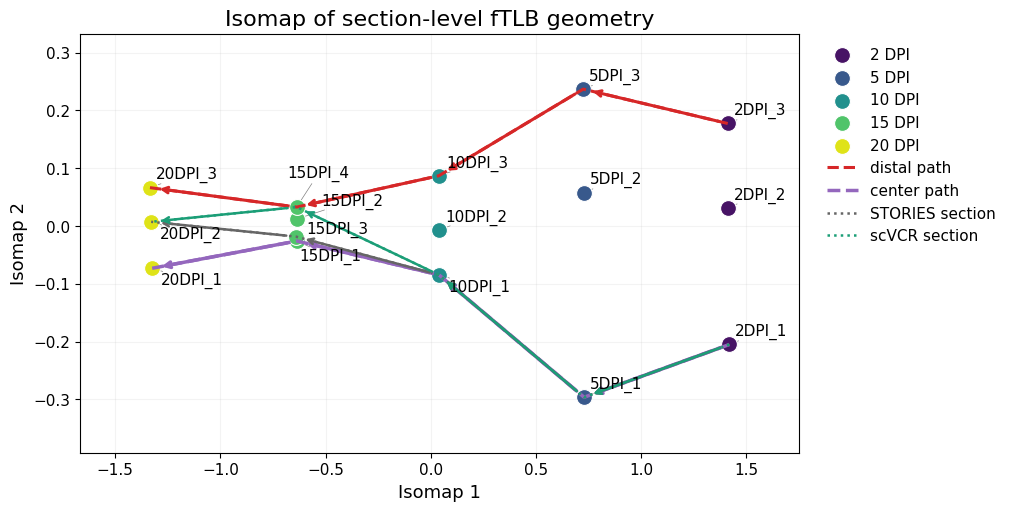

In [11]:
from scipy.sparse.csgraph import shortest_path

# ---------------- within-timepoint fTLB costs ----------------
within_costs = {}

for t in T:
    names = section_names_at(t)
    C = np.zeros((len(names), len(names)))

    for i, a in enumerate(names):
        A = section_at(t, a)
        for j in range(i + 1, len(names)):
            b = names[j]
            B = section_at(t, b)
            started = time.perf_counter()

            value, _, _ = fused_tlb(A, B, K=200, **ARGS)
            C[i, j] = C[j, i] = float(value)

            print(
                f"{t} DPI within: {a} <-> {b}: {C[i, j]:.4f} "
                f"({time.perf_counter() - started:.1f}s)",
                flush=True,
            )
            del B
            gc.collect()
        del A

    if not np.isfinite(C).all():
        raise ValueError(f"Nonfinite within-timepoint costs at {t} DPI")

    within_costs[t] = (C, names)
    pd.DataFrame(C, index=names, columns=names).to_csv(
        COST_DIR / f"{t}DPI_within.csv"
    )
    with open(OUT / "cost_tensors_within.pkl", "wb") as f:
        pickle.dump(within_costs, f)

# ---------------- section graph ----------------
nodes = [(t, s) for t in T for s in section_names_at(t)]
node_idx = {node: i for i, node in enumerate(nodes)}
n = len(nodes)

W = np.full((n, n), np.inf)
np.fill_diagonal(W, 0.0)

def to_dist(c):
    return np.sqrt(max(float(c), 0.0))

for t, (C, names) in within_costs.items():
    for i, a in enumerate(names):
        for j in range(i + 1, len(names)):
            u, v = node_idx[(t, a)], node_idx[(t, names[j])]
            W[u, v] = W[v, u] = to_dist(C[i, j])

for (ta, tb), (C, sa, sb) in cost_tensors_lower.items():
    for i, a in enumerate(sa):
        for j, b in enumerate(sb):
            u, v = node_idx[(ta, a)], node_idx[(tb, b)]
            W[u, v] = W[v, u] = to_dist(C[i, j])

# ---------------- geodesics + classical MDS ----------------
D_geo = shortest_path(W, directed=False)
if not np.isfinite(D_geo).all():
    raise ValueError("The section graph is disconnected.")

J = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * J @ (D_geo**2) @ J
eigvals, eigvecs = np.linalg.eigh(B)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
positive = eigvals > 1e-10
if positive.sum() < 2:
    raise ValueError("Fewer than two positive embedding dimensions.")
Z = eigvecs[:, positive][:, :2] * np.sqrt(eigvals[positive][:2])
var_expl = eigvals[positive][:2].sum() / eigvals[positive].sum()
print(f"\nMDS: 2D captures {var_expl:.0%} of positive eigenvalue mass")

pd.DataFrame(
    Z, index=[f"{t}|{s}" for t, s in nodes], columns=["Isomap1", "Isomap2"]
).to_csv(OUT / "isomap_coords.csv")

# ---------------- paths ----------------
path_STORIES = ['2DPI_1', '5DPI_1', '10DPI_1', '15DPI_3', '20DPI_2', '30DPI']
path_stVCR   = ['2DPI_1', '5DPI_1', '10DPI_1', '15DPI_4', '20DPI_2']

path_distal_rate = ['2DPI_3', '5DPI_3', '10DPI_3', '15DPI_4', '20DPI_3']
path_center_rate = ['2DPI_1', '5DPI_1', '10DPI_1', '15DPI_1', '20DPI_1']

rows = [
    ("distal path",     path_distal_rate),
    ("center path",     path_center_rate),
    ("STORIES section", path_STORIES),
    ("scVCR section",   path_stVCR),
]

def check_path(name, path):
    path = list(path)[:len(T)]          # keep only the retained time points
    if len(path) < len(T):
        raise ValueError(f"{name}: only {len(path)} steps for {len(T)} time points")
    for t, s in zip(T, path):
        if s not in section_names_at(t):
            raise ValueError(f"{name}: '{s}' is not a section at {t} DPI")
    return path

paths = {name: check_path(name, p) for name, p in rows}

# Optional: path probabilities, only if prob_cost_tensors exists for these T
def path_prob(path):
    tot = 0.0
    for (ta, a), (tb, b) in zip(zip(T, path), zip(T[1:], path[1:])):
        M, sa, sb = prob_cost_tensors[(ta, tb)]
        tot += float(M[list(sa).index(a), list(sb).index(b)])
    return float(np.exp(-tot))

try:
    probs = {name: path_prob(p) for name, p in paths.items()}
except (NameError, KeyError):
    probs = {}

styles = {
    "distal path":     dict(color="#d62728", linestyle="--", linewidth=2.2),
    "center path":     dict(color="#9467bd", linestyle="--",  linewidth=2.5),
    "STORIES section": dict(color="0.4",     linestyle=":", linewidth=1.8),
    "scVCR section":   dict(color="#1b9e77", linestyle=":", linewidth=1.8),
}


from adjustText import adjust_text

# ---------------- plot ----------------
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
time_colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(T)))

texts = []
for color, t in zip(time_colors, T):
    names = section_names_at(t)
    ids = [node_idx[(t, s)] for s in names]
    ax.scatter(Z[ids, 0], Z[ids, 1], s=130, color=color,
               edgecolor="white", linewidth=0.8, label=f"{t} DPI", zorder=3)
    for idx, sid in zip(ids, names):
        texts.append(ax.text(Z[idx, 0], Z[idx, 1], str(sid),
                             fontsize=11, fontweight="medium", zorder=6))

for name, path in paths.items():
    ids = [node_idx[(t, s)] for t, s in zip(T, path)]
    xy, st = Z[ids], styles[name]
    label = f"{name}  (P = {probs[name]:.2e})" if name in probs else name
    ax.plot(xy[:, 0], xy[:, 1], label=label, zorder=4, **st)
    for start, end in zip(xy[:-1], xy[1:]):
        ax.annotate("", xy=end, xytext=start, zorder=5,
                    arrowprops=dict(arrowstyle="->", color=st["color"],
                                    linewidth=st["linewidth"],
                                    shrinkA=7, shrinkB=7))

xpad = 0.12 * np.ptp(Z[:, 0])
ypad = 0.18 * np.ptp(Z[:, 1])
ax.set_xlim(Z[:, 0].min() - xpad, Z[:, 0].max() + xpad)
ax.set_ylim(Z[:, 1].min() - ypad, Z[:, 1].max() + ypad)

ax.set_title("Isomap of section-level fTLB geometry", fontsize=16)
ax.set_xlabel("Isomap 1", fontsize=13)
ax.set_ylabel("Isomap 2", fontsize=13)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.15)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=11)

# Spread labels after limits and legend are fixed
adjust_text(
    texts, x=Z[:, 0], y=Z[:, 1], ax=ax,
    expand=(1.3, 1.5),
    arrowprops=dict(arrowstyle="-", color="0.5", lw=0.5),
)

# fig.savefig(OUT / "isomap_sections.pdf", bbox_inches="tight")
plt.show()

REG_FRAC=0.0025: top-20 mass=41.01%
REG_FRAC=0.005: top-20 mass=24.60%
REG_FRAC=0.01: top-20 mass=14.55%
REG_FRAC=0.02: top-20 mass=9.96%


REG_FRAC=0.04: top-20 mass=7.94%


,shared_top10,top10_overlap_fraction,top10_Jaccard,same_top1,top1_section_agreement,mean_best_section_agreement,top10_probability_mass
reg_frac,,,,,,,
0.0025,14,0.7,0.538,True,1.0,0.93,0.410
0.0050,16,0.8,0.667,True,1.0,0.96,0.246
0.0100,20,1.0,1.000,True,1.0,1.00,0.146
0.0200,18,0.9,0.818,True,1.0,0.98,0.100
0.0400,18,0.9,0.818,True,1.0,0.98,0.079


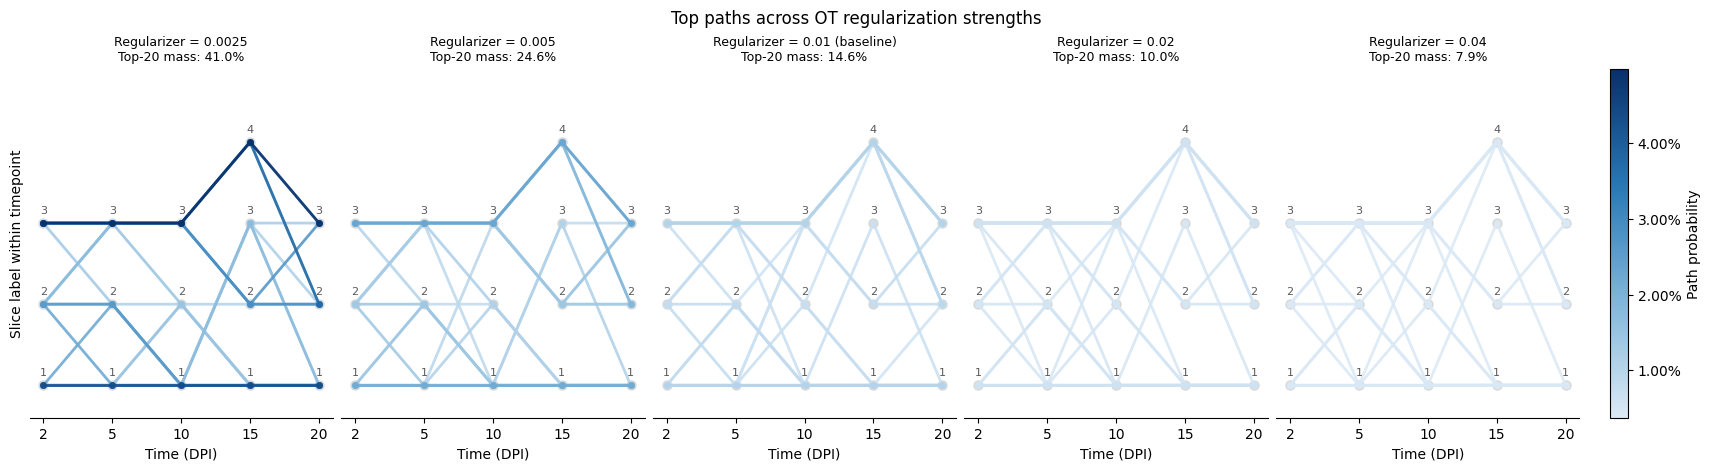

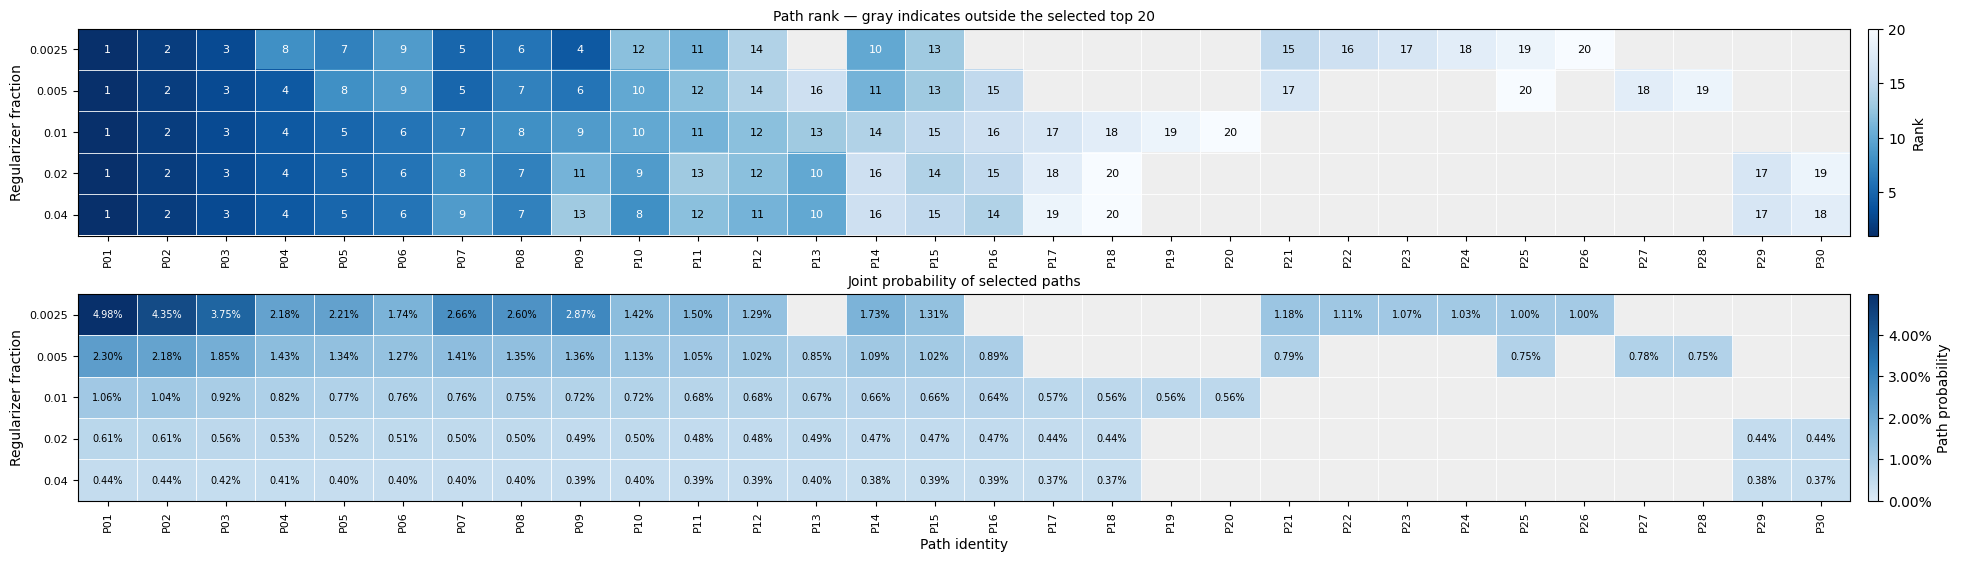

,2,5,10,15,20
path_label,,,,,
P01,2DPI_3,5DPI_3,10DPI_3,15DPI_4,20DPI_3
P02,2DPI_1,5DPI_1,10DPI_1,15DPI_1,20DPI_1
P03,2DPI_3,5DPI_3,10DPI_3,15DPI_4,20DPI_2
P04,2DPI_1,5DPI_2,10DPI_1,15DPI_1,20DPI_1
P05,2DPI_2,5DPI_1,10DPI_1,15DPI_1,20DPI_1
P06,2DPI_2,5DPI_3,10DPI_3,15DPI_4,20DPI_3
P07,2DPI_3,5DPI_3,10DPI_3,15DPI_2,20DPI_3
P08,2DPI_2,5DPI_2,10DPI_1,15DPI_1,20DPI_1
P09,2DPI_3,5DPI_3,10DPI_3,15DPI_2,20DPI_2


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from IPython.display import display

import ot

REG_FRACS = [0.0025, 0.005, 0.01, 0.02, 0.04]
BASE_REG = 0.01
N_PATHS = 20


# ---------------- Compute top-k paths for one regularizer ----------------
def top_paths_for_reg(reg_frac):
    section_names = {}
    transitions = {}
    initial_mass = None

    for ta, tb in zip(T[:-1], T[1:]):
        C, sa, sb = cost_tensors_lower[(ta, tb)]
        C = np.asarray(C, dtype=float)
        sa, sb = list(map(str, sa)), list(map(str, sb))

        if C.shape != (len(sa), len(sb)) or not np.isfinite(C).all():
            raise ValueError(f"Invalid costs at {ta}->{tb}")

        for t, names in [(ta, sa), (tb, sb)]:
            if t in section_names and section_names[t] != names:
                raise ValueError(f"Inconsistent section order at {t}")
            section_names[t] = names

        p = np.full(len(sa), 1 / len(sa))
        q = np.full(len(sb), 1 / len(sb))
        reg = reg_frac * max(float(C.max()), 1e-9)

        G = np.asarray(ot.sinkhorn(
            p, q, C, reg,
            method="sinkhorn_log",
            numItermax=50_000,
            stopThr=1e-10,
        ))

        error = max(
            np.max(np.abs(G.sum(axis=1) - p)),
            np.max(np.abs(G.sum(axis=0) - q)),
        )

        if (
            not np.isfinite(G).all()
            or np.any(G < 0)
            or error > 1e-6
        ):
            raise RuntimeError(
                f"reg_frac={reg_frac}, {ta}->{tb}: "
                f"invalid coupling; marginal error={error:.2e}"
            )

        if initial_mass is None:
            initial_mass = p

        transitions[(ta, tb)] = (
            G / G.sum(axis=1, keepdims=True)
        )

    best = {
        i: [(float(np.log(prob)), (i,))]
        for i, prob in enumerate(initial_mass)
        if prob > 0
    }

    for ta, tb in zip(T[:-1], T[1:]):
        P = transitions[(ta, tb)]
        next_best = {}

        for j in range(P.shape[1]):
            candidates = []

            for i, prefixes in best.items():
                if P[i, j] <= 0:
                    continue

                log_transition = float(np.log(P[i, j]))
                candidates.extend(
                    (lp + log_transition, indices + (j,))
                    for lp, indices in prefixes
                )

            candidates.sort(key=lambda item: (-item[0], item[1]))
            if candidates:
                next_best[j] = candidates[:N_PATHS]

        best = next_best

    ranked = sorted(
        [item for prefixes in best.values() for item in prefixes],
        key=lambda item: (-item[0], item[1]),
    )[:N_PATHS]

    if not ranked:
        raise RuntimeError(f"No paths at reg_frac={reg_frac}")

    log_probs = np.array([lp for lp, _ in ranked])
    relative = np.exp(log_probs - log_probs.max())
    weights = relative / relative.sum()

    records = []
    for rank, ((lp, indices), weight) in enumerate(
        zip(ranked, weights), start=1
    ):
        path = tuple(
            section_names[t][i] for t, i in zip(T, indices)
        )
        records.append({
            "reg_frac": reg_frac,
            "rank": rank,
            "path": path,
            "path_probability": float(np.exp(lp)),
            "ensemble_weight": float(weight),
        })

    return pd.DataFrame(records), section_names


results = {}
for reg_frac in REG_FRACS:
    results[reg_frac], section_names_sensitivity = (
        top_paths_for_reg(reg_frac)
    )
    print(
        f"REG_FRAC={reg_frac:g}: "
        f"top-{N_PATHS} mass="
        f"{results[reg_frac].path_probability.sum():.2%}",
        flush=True,
    )


# ---------------- Stability relative to the baseline ----------------
baseline = results[BASE_REG]
base_paths = baseline["path"].tolist()
base_set = set(base_paths)
base_map = base_paths[0]


def section_agreement(a, b):
    return np.mean([sa == sb for sa, sb in zip(a, b)])


summary_rows = []

for reg_frac, df in results.items():
    paths = df["path"].tolist()
    selected = set(paths)
    overlap = len(selected & base_set)

    summary_rows.append({
        "reg_frac": reg_frac,
        "shared_top10": overlap,
        "top10_overlap_fraction": overlap / len(base_set),
        "top10_Jaccard": overlap / len(selected | base_set),
        "same_top1": paths[0] == base_map,
        "top1_section_agreement": section_agreement(
            paths[0], base_map
        ),
        # Accommodates small path changes at one or two timepoints.
        "mean_best_section_agreement": np.mean([
            max(section_agreement(path, ref) for ref in base_paths)
            for path in paths
        ]),
        "top10_probability_mass": df.path_probability.sum(),
    })

stability_summary = pd.DataFrame(summary_rows).set_index("reg_frac")
display(stability_summary.round(3))


# ---------------- Pairwise top-k overlap ----------------
overlap_matrix = pd.DataFrame(
    index=REG_FRACS, columns=REG_FRACS, dtype=float
)

for ra in REG_FRACS:
    for rb in REG_FRACS:
        a = set(results[ra]["path"])
        b = set(results[rb]["path"])
        overlap_matrix.loc[ra, rb] = len(a & b) / len(a | b)


# ---------------- Track ranks of baseline top-ten paths ----------------
# Rank 11 denotes absence from the top ten, not its actual rank.
rank_matrix = np.full(
    (len(base_paths), len(REG_FRACS)), N_PATHS + 1, dtype=int
)

for j, reg_frac in enumerate(REG_FRACS):
    rank_lookup = dict(zip(
        results[reg_frac]["path"], results[reg_frac]["rank"]
    ))
    for i, path in enumerate(base_paths):
        rank_matrix[i, j] = rank_lookup.get(path, N_PATHS + 1)


# ---------------- Figures ----------------
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import PercentFormatter

regs = sorted(results)
reg_labels = [f"{r:g}" for r in regs]
names = section_names_sensitivity
x = np.arange(len(T))

prob_cmap = LinearSegmentedColormap.from_list(
    "probability_blue",
    ["#DCEAF6", "#80B6DA", "#2878B5", "#08306B"],
)

all_probabilities = np.concatenate([
    results[r]["path_probability"].to_numpy(dtype=float)
    for r in regs
])
pmin, pmax = all_probabilities.min(), all_probabilities.max()
pad = max(abs(pmin) * 0.01, 1e-12)
prob_norm = Normalize(
    vmin=pmin if pmax > pmin else pmin - pad,
    vmax=pmax if pmax > pmin else pmax + pad,
)

max_sections = max(len(names[t]) for t in T)


# ---------------- 1. Overlaid paths: color = joint probability ----------------
fig, axes = plt.subplots(
    1, len(regs),
    figsize=(3.4 * len(regs), 4.6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
axes = np.atleast_1d(axes)

for ax, reg in zip(axes, regs):
    df = results[reg]

    for k, t in enumerate(T):
        ax.scatter(
            np.full(len(names[t]), k),
            np.arange(len(names[t])),
            s=42, color="0.85", zorder=1,
        )

        for j, section in enumerate(names[t]):
            suffix = section.split("DPI", 1)[-1].lstrip("_")
            ax.annotate(
                suffix or "1",
                (k, j),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                color="0.35",
                zorder=30,
            )

    # Higher-probability paths appear on top.
    ordered = df.sort_values("path_probability")
    for z, (_, row) in enumerate(ordered.iterrows(), start=2):
        path = row["path"]
        y = [names[t].index(s) for t, s in zip(T, path)]

        ax.plot(
            x, y, "-o",
            color=prob_cmap(prob_norm(row["path_probability"])),
            linewidth=2,
            markersize=4,
            alpha=0.9,
            zorder=z,
        )

    baseline_text = " (baseline)" if reg == BASE_REG else ""
    ax.set_title(
        f"Regularizer = {reg:g}{baseline_text}\n"
        f"Top-{len(df)} mass: "
        f"{df.path_probability.sum():.1%}",
        fontsize=9,
    )
    ax.set_xticks(x, [str(t) for t in T])
    ax.set_yticks([])
    ax.set_ylim(-0.4, max_sections - 0.1)
    ax.set_xlabel("Time (DPI)")
    ax.spines[["top", "right", "left"]].set_visible(False)

axes[0].set_ylabel("Slice label within timepoint")

cb = fig.colorbar(
    ScalarMappable(norm=prob_norm, cmap=prob_cmap),
    ax=axes.tolist(),
    fraction=0.02,
    pad=0.02,
)
cb.set_label("Path probability")
cb.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

fig.suptitle("Top paths across OT regularization strengths")
plt.show()


# ---------------- 2. Horizontal path heatmaps ----------------
from matplotlib.colors import Normalize
from matplotlib.ticker import PercentFormatter

regs = sorted(results)
reg_labels = [f"{r:g}" for r in regs]

# Baseline paths first, followed by other selected paths.
all_paths = list(dict.fromkeys(
    results[BASE_REG]["path"].tolist()
    + [
        path
        for reg in regs
        for path in results[reg]["path"]
    ]
))
path_labels = [f"P{i + 1:02d}" for i in range(len(all_paths))]

# Rows = regularizers; columns = paths.
rank_values = np.full((len(regs), len(all_paths)), np.nan)
prob_values = np.full_like(rank_values, np.nan)

for i, reg in enumerate(regs):
    lookup = {
        row["path"]: row
        for _, row in results[reg].iterrows()
    }
    for j, path in enumerate(all_paths):
        if path in lookup:
            rank_values[i, j] = lookup[path]["rank"]
            prob_values[i, j] = lookup[path]["path_probability"]

n_selected = max(len(results[r]) for r in regs)

rank_cmap = plt.get_cmap("Blues_r").copy()
rank_cmap.set_bad("#EEEEEE")

heat_prob_cmap = prob_cmap.copy()
heat_prob_cmap.set_bad("#EEEEEE")

finite_probs = prob_values[np.isfinite(prob_values)]
prob_norm = Normalize(vmin=0, vmax=finite_probs.max())

fig, axes = plt.subplots(
    2, 1,
    figsize=(
        max(12, 0.65 * len(all_paths)),
        max(5, 0.9 * len(regs) + 1),
    ),
    sharex=True,
    constrained_layout=True,
)

im0 = axes[0].imshow(
    np.ma.masked_invalid(rank_values),
    cmap=rank_cmap,
    vmin=1,
    vmax=max(n_selected, 2),
    aspect="auto",
)

im1 = axes[1].imshow(
    np.ma.masked_invalid(prob_values),
    cmap=heat_prob_cmap,
    norm=prob_norm,
    aspect="auto",
)

for ax in axes:
    ax.set_xticks(
        range(len(all_paths)), path_labels, rotation=90
    )
    ax.set_yticks(range(len(regs)), reg_labels)
    ax.set_ylabel("Regularizer fraction")
    ax.tick_params(axis="x", labelbottom=True, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

    # Cell boundaries.
    ax.set_xticks(
        np.arange(-0.5, len(all_paths), 1), minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, len(regs), 1), minor=True
    )
    ax.grid(which="minor", color="white", linewidth=0.6)
    ax.tick_params(which="minor", bottom=False, left=False)

for i in range(len(regs)):
    for j in range(len(all_paths)):
        if not np.isfinite(rank_values[i, j]):
            continue

        axes[0].text(
            j, i,
            f"{int(rank_values[i, j])}",
            ha="center",
            va="center",
            fontsize=8,
            color=(
                "white"
                if rank_values[i, j] <= (n_selected + 1) / 2
                else "black"
            ),
        )

        axes[1].text(
            j, i,
            f"{prob_values[i, j]:.2%}",
            ha="center",
            va="center",
            fontsize=7,
            color=(
                "white"
                if prob_norm(prob_values[i, j]) > 0.55
                else "black"
            ),
        )

axes[0].set_title(
    f"Path rank — gray indicates outside the selected top {n_selected}",
    fontsize=10,
)
axes[1].set_title(
    "Joint probability of selected paths",
    fontsize=10,
)
axes[1].set_xlabel("Path identity")

fig.colorbar(
    im0,
    ax=axes[0],
    label="Rank",
    fraction=0.02,
    pad=0.01,
)
cb = fig.colorbar(
    im1,
    ax=axes[1],
    label="Path probability",
    fraction=0.02,
    pad=0.01,
)
cb.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.show()

# Path identity key.
path_key = pd.DataFrame([
    {
        "path_label": label,
        **{str(t): section for t, section in zip(T, path)},
    }
    for label, path in zip(path_labels, all_paths)
]).set_index("path_label")

display(path_key)